# 02｜資料準備：清理、探索與轉換

本 notebook 讀取專案中的 `fccl_thickness_dataset.csv`，執行資料品質檢查、探索性資料分析（EDA）、特徵轉換，最後匯出 CSV。資料為合成 FCCL 製程紀錄，刻意注入的異常、QC 標記及原有缺值都會保留，不會無依據地刪除或填補。

輸出位置：`data/processed/`。請依序執行所有程式碼儲存格。

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

# 從目前目錄或上層目錄尋找原始資料。
source_name = "fccl_thickness_dataset.csv"
source_path = next((p / source_name for p in [Path.cwd(), *Path.cwd().parents] if (p / source_name).exists()), None)
if source_path is None:
    raise FileNotFoundError(f"找不到 {source_name}，請確認目前工作目錄位於專案內。")
output_dir = source_path.parent / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# 優先使用系統已安裝的中文字型，確保圖表標題和座標軸能顯示中文。
font_candidates = ["Microsoft JhengHei", "Microsoft YaHei", "Noto Sans CJK TC", "Noto Sans CJK SC", "PingFang TC", "SimHei", "Arial Unicode MS"]
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next((name for name in font_candidates if name in installed_fonts), None)
if chinese_font:
    plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
else:
    warnings.warn("找不到中文字型，圖表中文可能顯示為方框。請安裝 Microsoft JhengHei 或 Noto Sans CJK TC，重新啟動 kernel 後再執行。")
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid")
print(f"來源檔案：{source_path}")
print(f"輸出資料夾：{output_dir}")
print(f"圖表中文字型：{chinese_font or '未找到'}")

來源檔案：c:\Users\Acer_Yi\Desktop\workspace\fccl\fccl_thickness_dataset.csv
輸出資料夾：c:\Users\Acer_Yi\Desktop\workspace\fccl\data\processed
圖表中文字型：Microsoft JhengHei


## 1. 載入與初步檢視

查看資料規模、欄位型態、缺值與重複紀錄，並將樣本日期轉為日期型態。

In [2]:
df = pd.read_csv(source_path)
print(f"資料列數：{len(df):,}；欄位數：{df.shape[1]}")
display(df.head())
display(pd.DataFrame({"資料型態": df.dtypes.astype(str), "缺值數": df.isna().sum(), "缺值比例": df.isna().mean().round(3)}))
print(f"完全重複列：{df.duplicated().sum()}")
if "Batch_ID" in df:
    print(f"重複批次 ID：{df['Batch_ID'].duplicated().sum()}")
df["Sample_Date"] = pd.to_datetime(df["Sample_Date"], errors="coerce")
print(f"無法解析的樣本日期：{df['Sample_Date'].isna().sum()}")

資料列數：492；欄位數：50


,Month,Line,Product_Model,Batch_ID,Batch_Area_m2,Batch_Length_m,Model_Batch_Sequence,Sample_Date,Measurement_Method,Nominal_Thickness_um,...,wet_target,wet_actual,temp_target,temp_actual,pressure_target,pressure_actual,cure_target,cure_actual,rewind_target,rewind_actual
0,2025-10,1L,FCCL-1L-18/25,202510-1L-1825-001,10000,20000.0,1,2025-10-01,Mechanical_Contact_Simulated,55.0,...,105.0,104.180,365.0,365.280,260.0,259.507,210.0,209.979,43.0,42.780
1,2025-10,1L,FCCL-1L-18/25,202510-1L-1825-002,10000,20000.0,2,2025-10-03,Mechanical_Contact_Simulated,55.0,...,105.0,105.230,365.0,365.904,260.0,260.672,210.0,212.698,43.0,42.895
2,2025-10,1L,FCCL-1L-18/25,202510-1L-1825-003,10000,20000.0,3,2025-10-06,Mechanical_Contact_Simulated,55.0,...,105.0,105.043,365.0,365.633,260.0,260.985,210.0,208.164,43.0,42.918
3,2025-10,1L,FCCL-1L-18/25,202510-1L-1825-004,10000,20000.0,4,2025-10-09,Mechanical_Contact_Simulated,55.0,...,105.0,104.286,365.0,362.986,260.0,260.776,210.0,210.179,43.0,43.178
4,2025-10,1L,FCCL-1L-12/12,202510-1L-1212-001,10000,20000.0,1,2025-10-11,Mechanical_Contact_Simulated,24.0,...,50.4,50.376,365.0,361.305,190.0,188.350,210.0,208.333,27.0,26.838


,資料型態,缺值數,缺值比例
Month,str,0,0.00
Line,str,0,0.00
Product_Model,str,0,0.00
Batch_ID,str,0,0.00
Batch_Area_m2,int64,0,0.00
Batch_Length_m,float64,0,0.00
Model_Batch_Sequence,int64,0,0.00
Sample_Date,str,0,0.00
Measurement_Method,str,0,0.00
Nominal_Thickness_um,float64,0,0.00


完全重複列：0
重複批次 ID：0
無法解析的樣本日期：0


## 2. 資料清理與品質檢查

修剪文字前後空白、移除完全重複列，保留原始缺值和異常標記。檢查厚度摘要是否與 10 個量測點一致，以及規格界限是否對稱。

In [3]:
text_cols = df.select_dtypes(include="object").columns
df[text_cols] = df[text_cols].apply(lambda col: col.str.strip())
df = df.drop_duplicates().copy()
point_cols = [f"Point_{i}_um" for i in range(1, 11)]
points = df[point_cols]
checks = pd.DataFrame({
    "平均值相符（誤差 ≤ 0.001）": (points.mean(axis=1) - df["Thickness_Mean_um"]).abs() <= 0.001,
    "標準差相符（誤差 ≤ 0.001）": (points.std(axis=1) - df["Thickness_Std_um"]).abs() <= 0.001,
    "全距相符（誤差 ≤ 0.001）": (points.max(axis=1) - points.min(axis=1) - df["Thickness_Range_um"]).abs() <= 0.001,
    "規格界限對稱": ((df["Nominal_Thickness_um"] - df["LSL_um"]) - (df["USL_um"] - df["Nominal_Thickness_um"])).abs() <= 0.001,
})
display(pd.DataFrame({"通過筆數": checks.sum(), "未通過筆數": (~checks).sum()}))
display(df.isna().sum().loc[lambda s: s.gt(0)].rename("保留缺值數").to_frame())
display(df["Injected_Anomaly"].value_counts(dropna=False).rename("筆數").to_frame())
display(df["QC_Result"].value_counts(dropna=False).rename("筆數").to_frame())

C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\2984441914.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


,通過筆數,未通過筆數
平均值相符（誤差 ≤ 0.001）,492,0
標準差相符（誤差 ≤ 0.001）,492,0
全距相符（誤差 ≤ 0.001）,492,0
規格界限對稱,492,0


,保留缺值數
temp_target,192
temp_actual,192


,筆數
Injected_Anomaly,
0,411
1,81


,筆數
QC_Result,
PASS,411
NG,81


## 3. 探索性資料分析（EDA）

下方以中文標示批次平均厚度分布、每月注入異常比例和各產線 QC 結果比例。圖表中文字型已在第一個儲存格設定。

,數值
批次數,492
產品型號數,10
產線數,3
注入異常批次數,81
NG 批次數,81


C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 21402 (\N{CJK UNIFIED IDEOGRAPH-539A}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer_Yi\AppData\Local\Temp\ipykernel_22948\4237325379.py:15: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT 

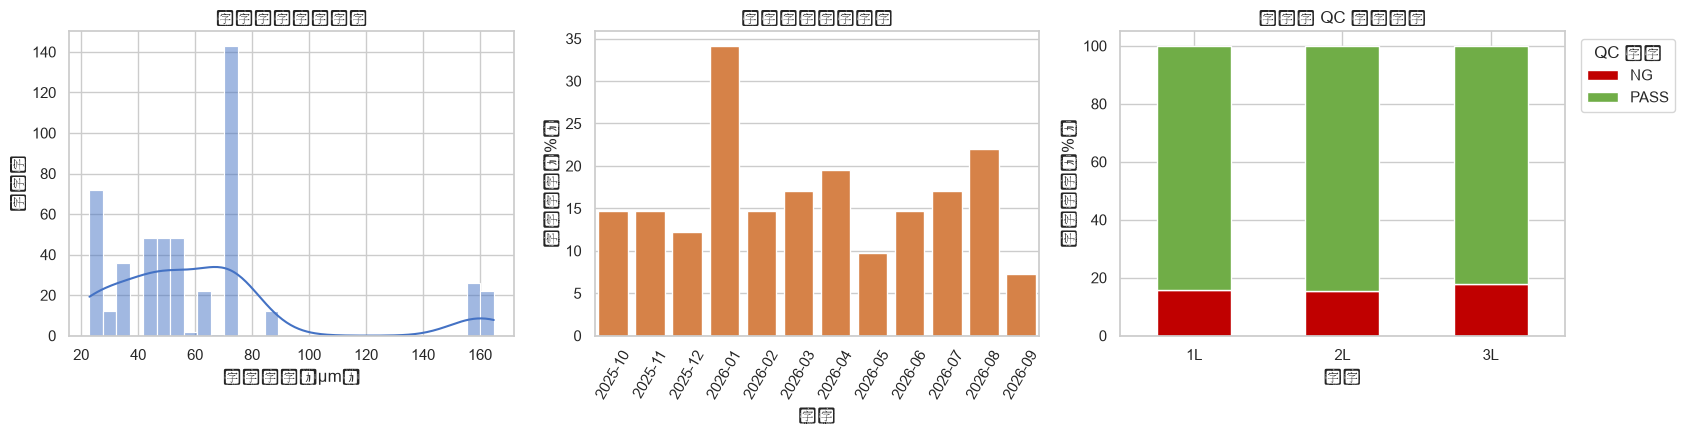

QC_Result,NG,PASS,All
異常模式,,,
Center_Bulge,23,0,23
Drift,12,0,12
Local_Spike,19,0,19
Mean_Shift,9,0,9
Normal,0,411,411
Wedge,18,0,18
All,81,411,492


In [4]:
display(pd.Series({"批次數": len(df), "產品型號數": df["Product_Model"].nunique(), "產線數": df["Line"].nunique(), "注入異常批次數": int(df["Injected_Anomaly"].sum()), "NG 批次數": int(df["QC_Result"].eq("NG").sum())}, name="數值").to_frame())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["Thickness_Mean_um"], bins=30, kde=True, ax=axes[0], color="#4472C4")
axes[0].set(title="批次平均厚度分布", xlabel="平均厚度（µm）", ylabel="批次數")
monthly = df.groupby("Month", sort=True)["Injected_Anomaly"].mean().mul(100).rename("異常比例").reset_index()
sns.barplot(data=monthly, x="Month", y="異常比例", ax=axes[1], color="#ED7D31")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set(title="每月注入異常比例", xlabel="月份", ylabel="異常比例（%）")
qc = pd.crosstab(df["Line"], df["QC_Result"], normalize="index").mul(100)
colors = [{"NG": "#C00000", "PASS": "#70AD47"}.get(label, "#4472C4") for label in qc.columns]
qc.plot(kind="bar", stacked=True, ax=axes[2], color=colors)
axes[2].set(title="各產線 QC 結果比例", xlabel="產線", ylabel="批次比例（%）")
axes[2].legend(title="QC 結果", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(pd.crosstab(df["Anomaly_Pattern"], df["QC_Result"], margins=True).rename_axis("異常模式"))

## 4. 特徵轉換

產生批次層級清理資料、每個量測點一列的長格式資料，以及實際值相對目標值的偏差和偏差百分比。偏差定義為「實際值 − 目標值」，缺值維持空白。

In [5]:
# 清理資料：格式化日期，保留其他來源欄位。
cleaned = df.copy()
cleaned["Sample_Date"] = cleaned["Sample_Date"].dt.strftime("%Y-%m-%d")

# 將 10 個測點攤平成長格式，並依批次規格判定是否合格。
measurements = df.melt(id_vars=[c for c in df.columns if c not in point_cols], value_vars=point_cols, var_name="Measurement_Point", value_name="Measured_Thickness_um")
measurements["Measurement_Point_Number"] = measurements["Measurement_Point"].str.extract(r"(\d+)").astype(int)
measurements["Within_Spec"] = measurements["Measured_Thickness_um"].between(measurements["LSL_um"], measurements["USL_um"], inclusive="both")
measurements["Sample_Date"] = measurements["Sample_Date"].dt.strftime("%Y-%m-%d")

# 對每組目標值和實際值計算差值與百分比差值。
process_features = df[["Batch_ID", "Sample_Date", "Month", "Line", "Product_Model", "Injected_Anomaly", "QC_Result"]].copy()
for target_col in [c for c in df.columns if c.endswith("_target")]:
    base = target_col.removesuffix("_target")
    actual_col = f"{base}_actual"
    if actual_col in df.columns:
        process_features[f"{base}_deviation"] = df[actual_col] - df[target_col]
        process_features[f"{base}_deviation_pct"] = np.where(df[target_col].ne(0), (df[actual_col] - df[target_col]) / df[target_col] * 100, np.nan)
process_features["Sample_Date"] = process_features["Sample_Date"].dt.strftime("%Y-%m-%d")
display(measurements[["Batch_ID", "Measurement_Point", "Measured_Thickness_um", "Within_Spec"]].head())
display(process_features.head())

,Batch_ID,Measurement_Point,Measured_Thickness_um,Within_Spec
0,202510-1L-1825-001,Point_1_um,55.15,True
1,202510-1L-1825-002,Point_1_um,54.98,True
2,202510-1L-1825-003,Point_1_um,54.83,True
3,202510-1L-1825-004,Point_1_um,55.16,True
4,202510-1L-1212-001,Point_1_um,23.84,True


,Batch_ID,Sample_Date,Month,Line,Product_Model,Injected_Anomaly,QC_Result,speed_deviation,speed_deviation_pct,unwind_deviation,...,wet_deviation,wet_deviation_pct,temp_deviation,temp_deviation_pct,pressure_deviation,pressure_deviation_pct,cure_deviation,cure_deviation_pct,rewind_deviation,rewind_deviation_pct
0,202510-1L-1825-001,2025-10-01,2025-10,1L,FCCL-1L-18/25,0,PASS,0.010,0.181818,-0.237,...,-0.820,-0.780952,0.280,0.076712,-0.493,-0.189615,-0.021,-0.010000,-0.220,-0.511628
1,202510-1L-1825-002,2025-10-03,2025-10,1L,FCCL-1L-18/25,0,PASS,0.040,0.727273,-0.035,...,0.230,0.219048,0.904,0.247671,0.672,0.258462,2.698,1.284762,-0.105,-0.244186
2,202510-1L-1825-003,2025-10-06,2025-10,1L,FCCL-1L-18/25,0,PASS,0.004,0.072727,0.050,...,0.043,0.040952,0.633,0.173425,0.985,0.378846,-1.836,-0.874286,-0.082,-0.190698
3,202510-1L-1825-004,2025-10-09,2025-10,1L,FCCL-1L-18/25,0,PASS,-0.012,-0.218182,-0.105,...,-0.714,-0.680000,-2.014,-0.551781,0.776,0.298462,0.179,0.085238,0.178,0.413953
4,202510-1L-1212-001,2025-10-11,2025-10,1L,FCCL-1L-12/12,0,PASS,0.021,0.291667,0.059,...,-0.024,-0.047619,-3.695,-1.012329,-1.650,-0.868421,-1.667,-0.793810,-0.162,-0.600000


## 5. 匯出 CSV

使用 UTF-8 with BOM（`utf-8-sig`）編碼，方便 Windows Excel 正確辨識文字。重複執行會覆寫同名檔案。

In [6]:
outputs = {"fccl_cleaned.csv": cleaned, "fccl_measurements_long.csv": measurements, "fccl_process_deviation_features.csv": process_features}
for filename, data in outputs.items():
    destination = output_dir / filename
    data.to_csv(destination, index=False, encoding="utf-8-sig")
    print(f"已匯出：{destination}（{len(data):,} 列 × {data.shape[1]} 欄）")

已匯出：c:\Users\Acer_Yi\Desktop\workspace\fccl\data\processed\fccl_cleaned.csv（492 列 × 50 欄）
已匯出：c:\Users\Acer_Yi\Desktop\workspace\fccl\data\processed\fccl_measurements_long.csv（4,920 列 × 44 欄）
已匯出：c:\Users\Acer_Yi\Desktop\workspace\fccl\data\processed\fccl_process_deviation_features.csv（492 列 × 27 欄）


## 輸出檔案與注意事項

- `fccl_cleaned.csv`：保留原始欄位的批次層級清理資料。
- `fccl_measurements_long.csv`：厚度測點長格式資料，每批最多 10 列。
- `fccl_process_deviation_features.csv`：批次層級製程偏差特徵。
- 溫度缺值、異常標記與 QC 結果均會保留。`Potential_Root_Cause_Synthetic` 是合成資料中的假設，不代表實際調查結論。
- 若中文仍顯示為方框，請安裝 Microsoft JhengHei 或 Noto Sans CJK TC，重新啟動 Jupyter kernel 後再執行。